# Imports

In [3]:
from pyspark.sql import functions as F
from pyspark.sql import Window

import matplotlib.pyplot as plt
import pandas as pd

from presyo_ph.medallion.gold import load_gold_table

from presyo_ph.spark import get_spark_session

In [ ]:
spark = get_spark_session()

# Load Tables

In [5]:
market_df = load_gold_table(spark, "market_monthly_prices")
regional_df = load_gold_table(spark, "regional_monthly_prices")
national_df = load_gold_table(spark, "national_monthly_prices")
growth_df = load_gold_table(spark, "national_commodity_growth")

Gold table loaded: market_monthly_prices (local)
Gold table loaded: regional_monthly_prices (local)
Gold table loaded: national_monthly_prices (local)
Gold table loaded: national_commodity_growth (local)


# Overview

In [6]:
print(f"Market records:   {market_df.count():,}")
print(f"Regional records: {regional_df.count():,}")
print(f"National records: {national_df.count():,}")
print(f"Growth records:   {growth_df.count():,}")

market_df.select(
    F.min("price_date").alias("earliest_date"),
    F.max("price_date").alias("latest_date"),
    F.countDistinct("geo_id").alias("unique_markets"),
    F.countDistinct("adm1_name").alias("unique_regions"),
    F.countDistinct("commodity").alias("commodities"),
).show(truncate=False)

26/11/05 16:06:09 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

Market records:   222,687
Regional records: 23,862
National records: 1,620
Growth records:   9
+-------------+-----------+--------------+--------------+-----------+
|earliest_date|latest_date|unique_markets|unique_regions|commodities|
+-------------+-----------+--------------+--------------+-----------+
|2007-01-01   |2025-11-01 |109           |18            |9          |
+-------------+-----------+--------------+--------------+-----------+



## Commodity Coverage

In [8]:
commodity_coverage = (
    market_df
    .groupBy("commodity")
    .agg(
        F.count("*").alias("total_records"),
        F.count("price").alias("available_prices"),
        F.sum(
            F.col("price").isNull().cast("integer")
        ).alias("missing_prices"),
        F.sum(
            F.col("was_imputed").cast("integer")
        ).alias("imputed_prices"),
        F.countDistinct("geo_id").alias("markets"),
        F.min("price_date").alias("first_observation"),
        F.max("price_date").alias("last_observation"),
    )
    .withColumn(
        "availability_pct",
        F.round(
            F.col("available_prices") / F.col("total_records") * 100,
            2,
        ),
    )
    .orderBy("commodity")
)

commodity_coverage.toPandas()

,commodity,total_records,available_prices,missing_prices,imputed_prices,markets,first_observation,last_observation,availability_pct
0,beans,24743,4271,20472,1470,109,2007-01-01,2025-11-01,17.26
1,cabbage,24743,6204,18539,2746,109,2007-01-01,2025-11-01,25.07
2,carrots,24743,6518,18225,2957,109,2007-01-01,2025-11-01,26.34
3,eggs,24743,6152,18591,83,109,2007-01-01,2025-11-01,24.86
4,garlic,24743,3539,21204,127,109,2007-01-01,2025-11-01,14.30
5,onions,24743,6287,18456,95,109,2007-01-01,2025-11-01,25.41
6,potatoes,24743,3110,21633,99,109,2007-01-01,2025-11-01,12.57
7,rice,24743,7442,17301,58,109,2007-01-01,2025-11-01,30.08
8,tomatoes,24743,6982,17761,77,109,2007-01-01,2025-11-01,28.22


### Results
- Commodities all have low availability percentages, highlighting missing data from various dates.
- Observation dates remain consistent; as well as the number of markets observed per commodity.
- Commodities with highest and lowest historical data: rice (30.08% availability) and potatoes (12.57% availability)

## Commodity Statistics

In [14]:
commodity_statistics = (
    market_df
    .filter(F.col("price").isNotNull())
    .groupBy("commodity", "currency")
    .agg(
        F.count("price").alias("observations"),
        F.avg("price").alias("mean_price"),
        F.expr("percentile_approx(price, 0.5)").alias("median_price"),
        F.stddev("price").alias("stddev_price"),
        F.min("price").alias("minimum_price"),
        F.max("price").alias("maximum_price"),
    )
    .withColumn(
        "mean_median_diff",
        F.abs(F.col("mean_price") - F.col("median_price"))
    )
    .withColumn(
    "mean_median_diff_pct",
    (
        F.col("mean_median_diff") /
        ((F.col("mean_price") + F.col("median_price")) / 2)
    ) * 100
)
)

# Full statistics
commodity_statistics.orderBy(
    F.col("mean_median_diff_pct").desc()
).toPandas()

,commodity,currency,observations,mean_price,median_price,stddev_price,minimum_price,maximum_price,mean_median_diff,mean_median_diff_pct
0,garlic,PHP,3539,171.562834,154.50,58.932840,80.91,594.44,17.062834,10.465979
1,tomatoes,PHP,6982,66.621629,60.63,33.708315,7.45,285.00,5.991629,9.416978
2,onions,PHP,6287,133.434899,122.86,65.742685,24.50,617.50,10.574899,8.252134
3,potatoes,PHP,3110,38.089966,35.74,15.928887,10.00,110.00,2.349966,6.365887
4,carrots,PHP,6518,96.342947,91.67,38.731240,14.20,300.00,4.672947,4.970878
5,cabbage,PHP,6204,74.507411,72.14,30.850932,7.52,198.75,2.367411,3.228712
6,rice,PHP,7442,40.009260,38.88,6.390912,20.00,60.29,1.129260,2.862900
7,beans,PHP,4271,99.347089,100.00,15.264328,55.49,230.77,0.652911,0.655050
8,eggs,PHP,6152,7.237849,7.25,1.621270,3.99,25.00,0.012151,0.167745


### Results
- Mean and median of each commodity remain relatively close with maximum difference of 10.46% and a minimum difference of 0.17%
- This suggests that the data does not have a skewed distribution or extreme prices.

## Price Distributions

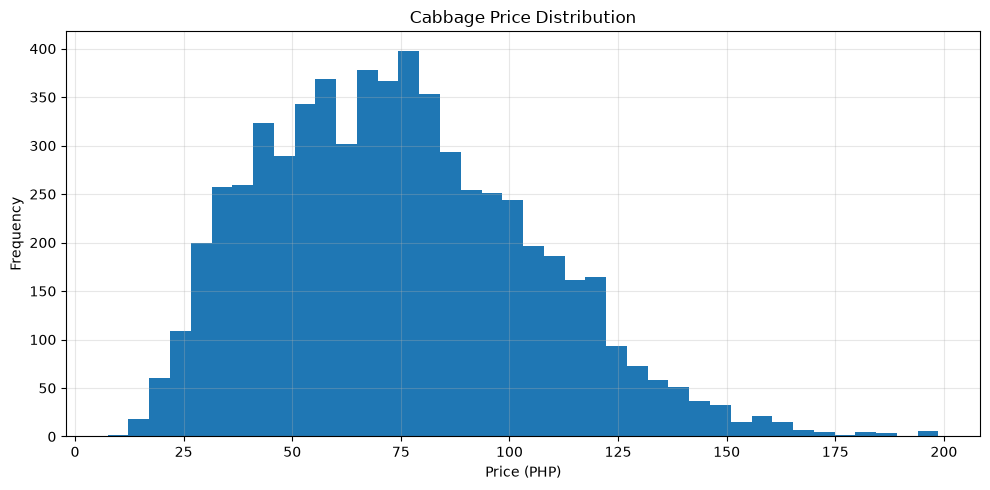

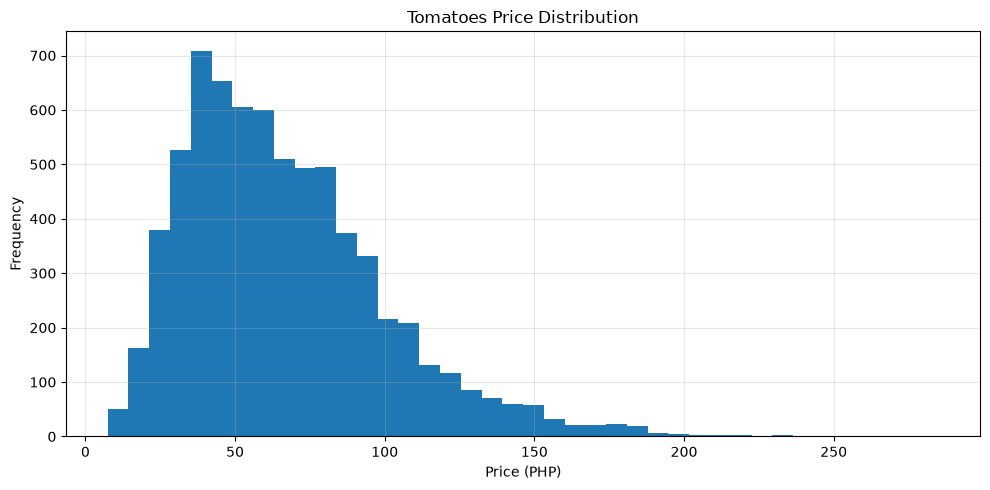

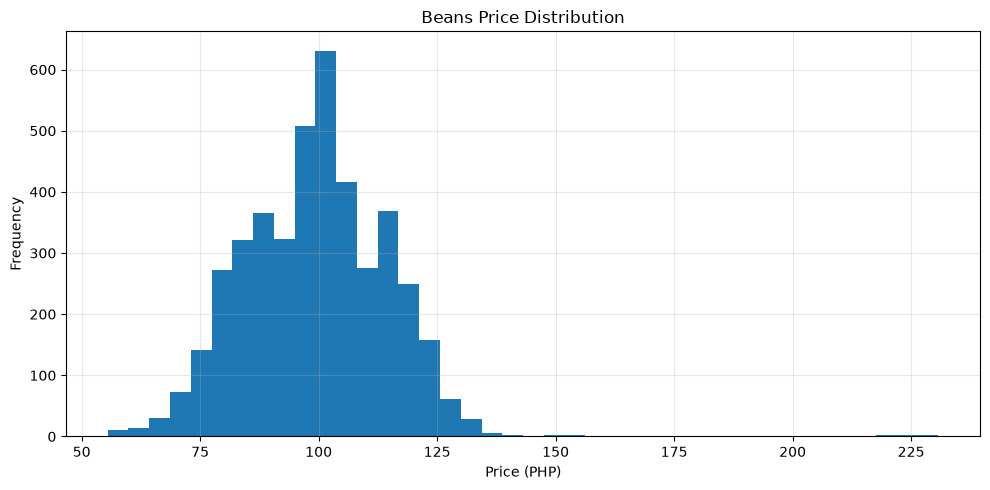

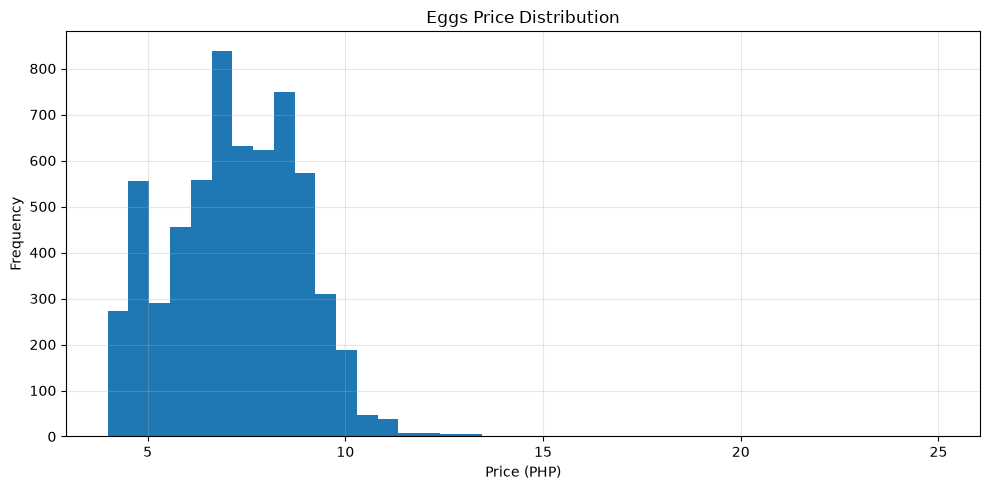

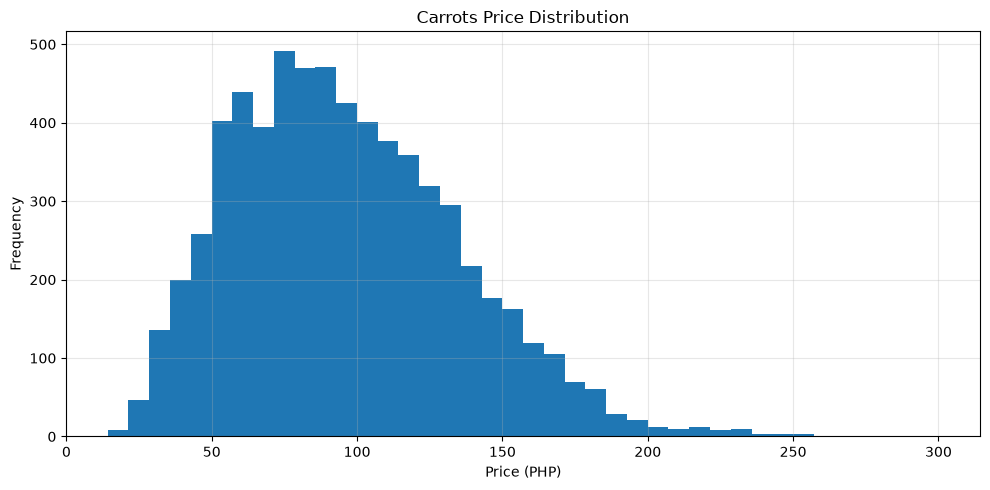

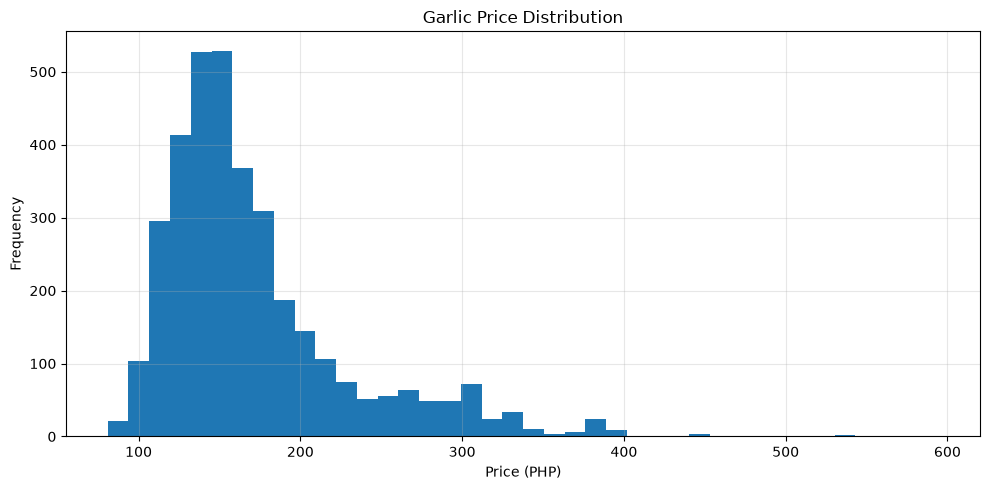

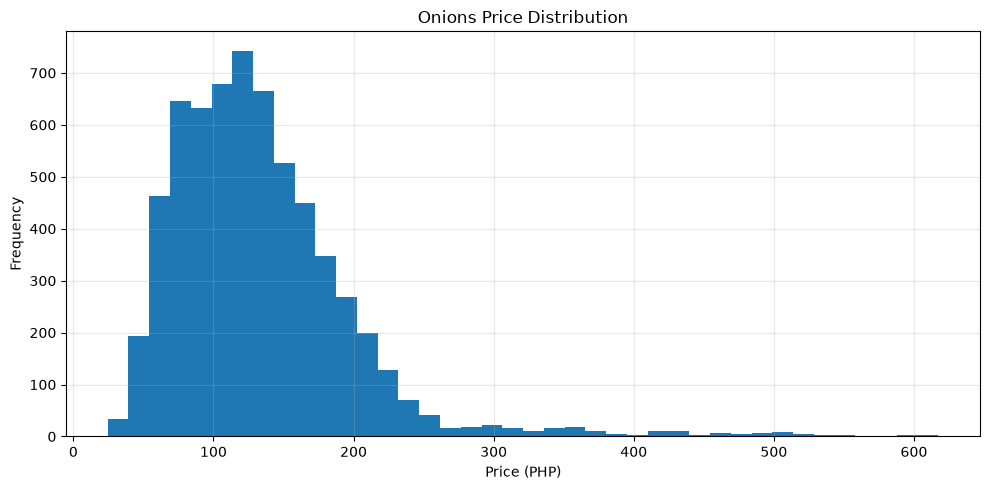

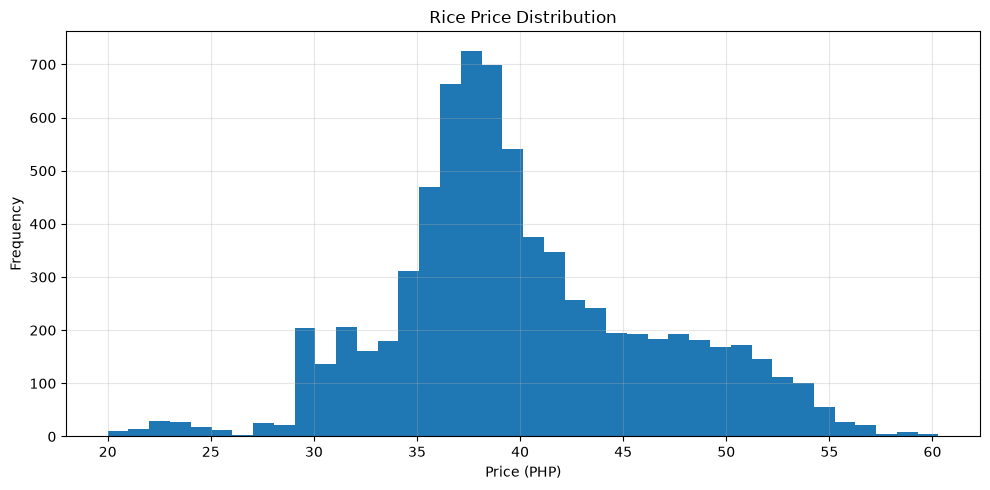

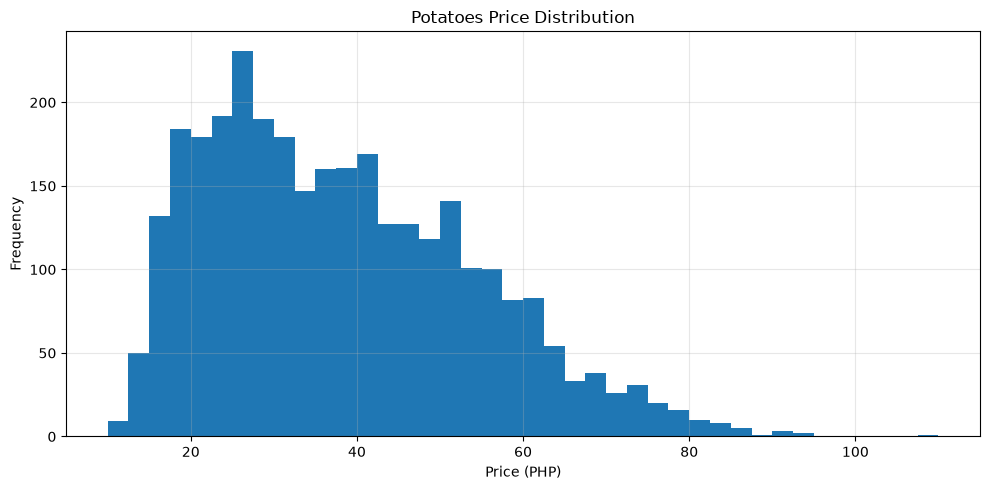

In [16]:
commodities = [
    row["commodity"]
    for row in market_df.select("commodity").distinct().collect()
]

for commodity in commodities:
    pdf = (
        market_df
        .filter(
            (F.col("commodity") == commodity)
            & F.col("price").isNotNull()
        )
        .select("price")
        .toPandas()
    )

    if pdf.empty:
        continue

    plt.figure(figsize=(10, 5))
    plt.hist(pdf["price"], bins=40)
    plt.title(f"{commodity.title()} Price Distribution")
    plt.xlabel("Price (PHP)")
    plt.ylabel("Frequency")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Results
- General distribution across commodities are varied, with most experiencing right skewedness.
- This suggests that food prices have been relatively close but occasional periods of high prices pull the mean upward.
- Possible causes may be: supply shortages, seasonal demands, and inflation.

## National Price Distribution

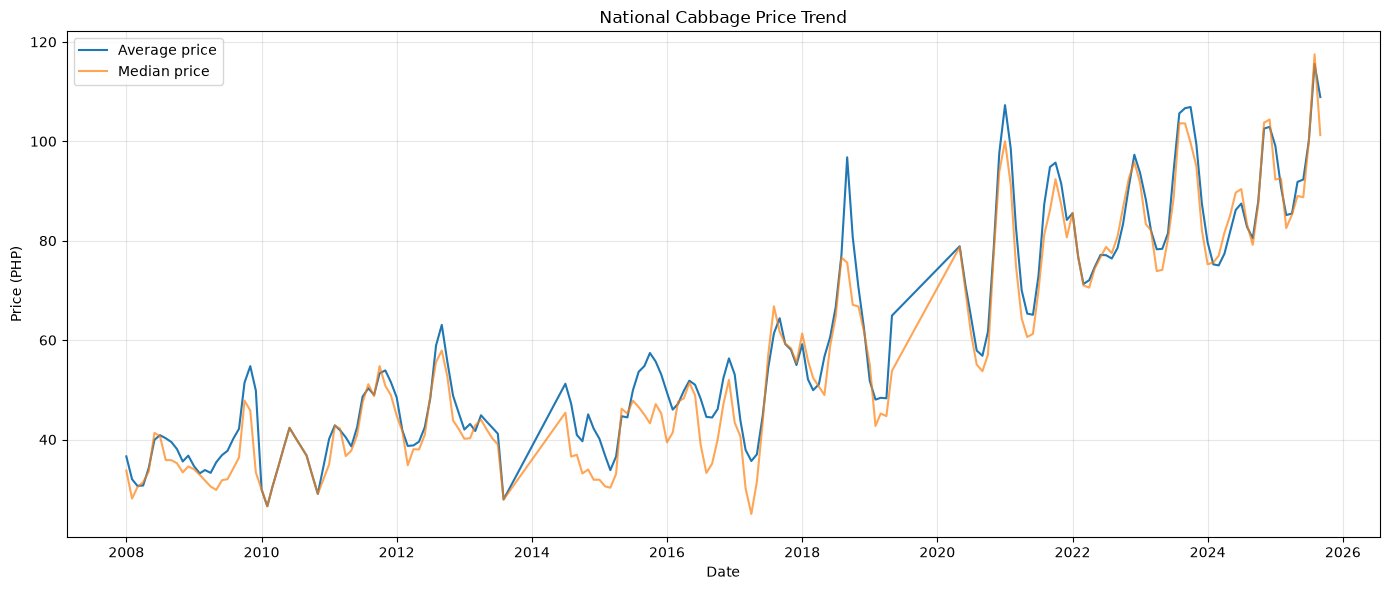

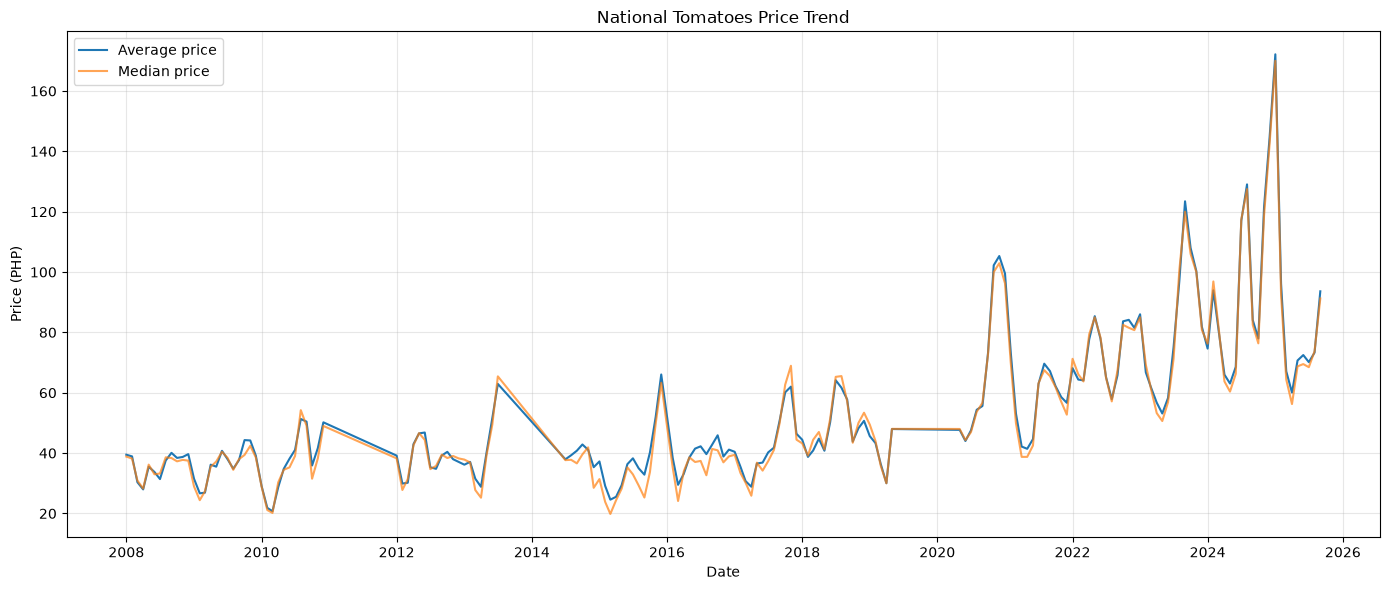

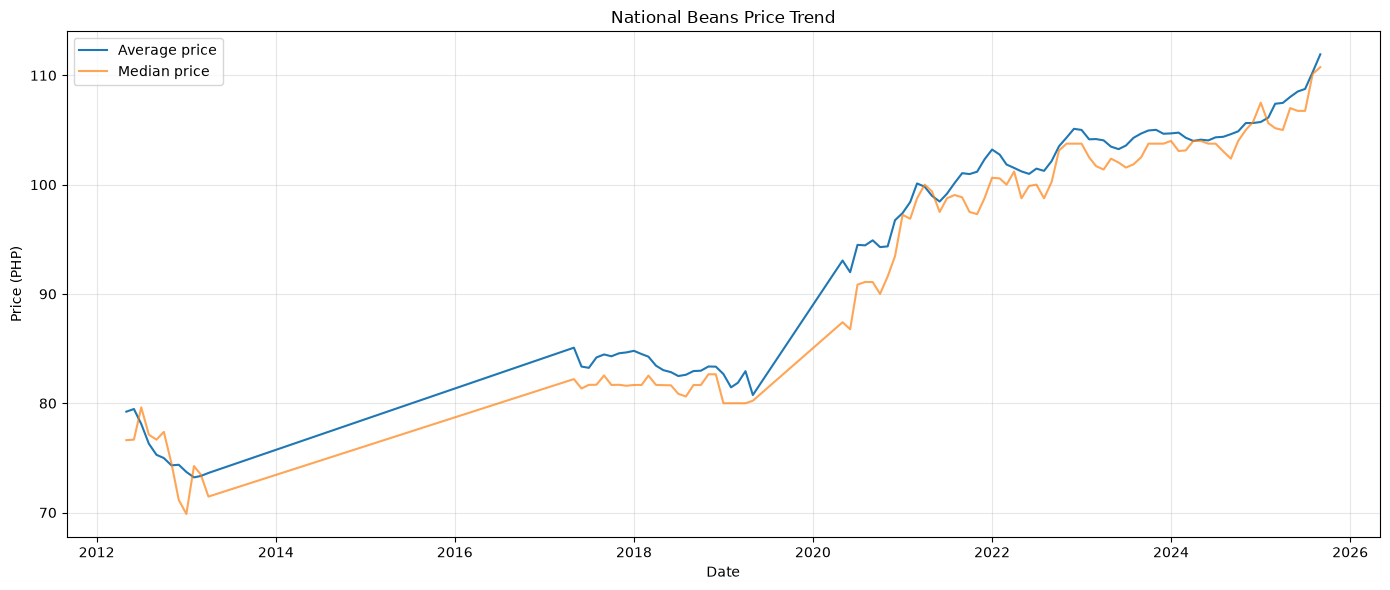

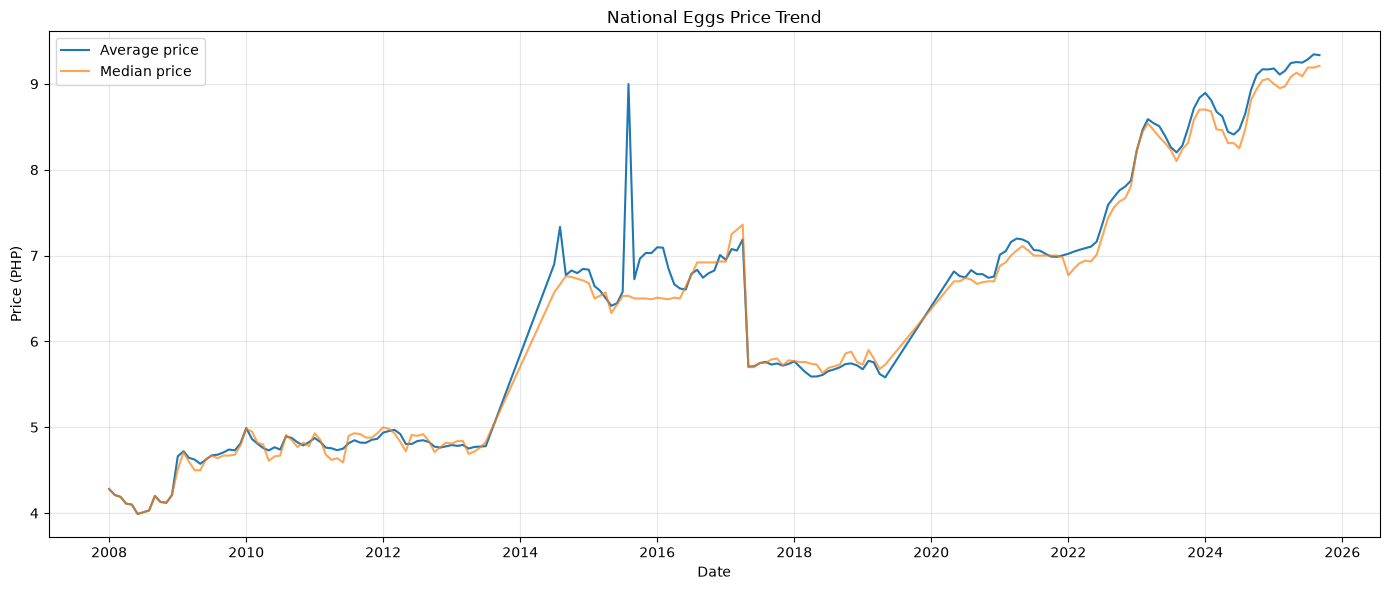

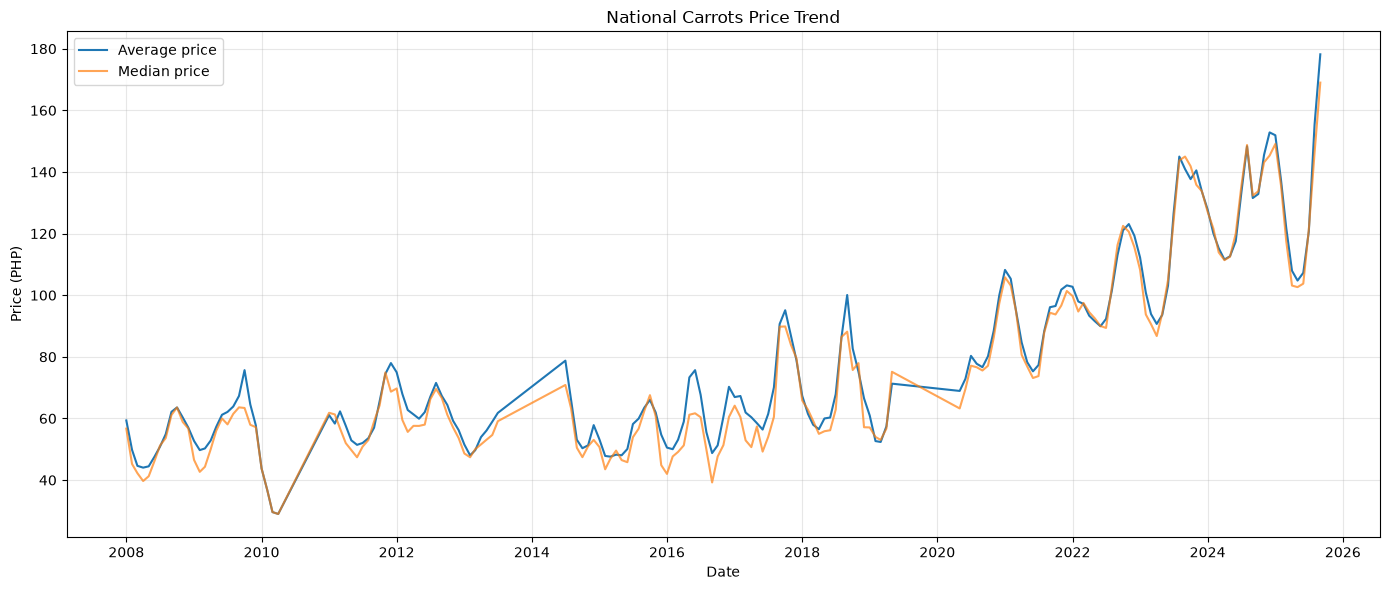

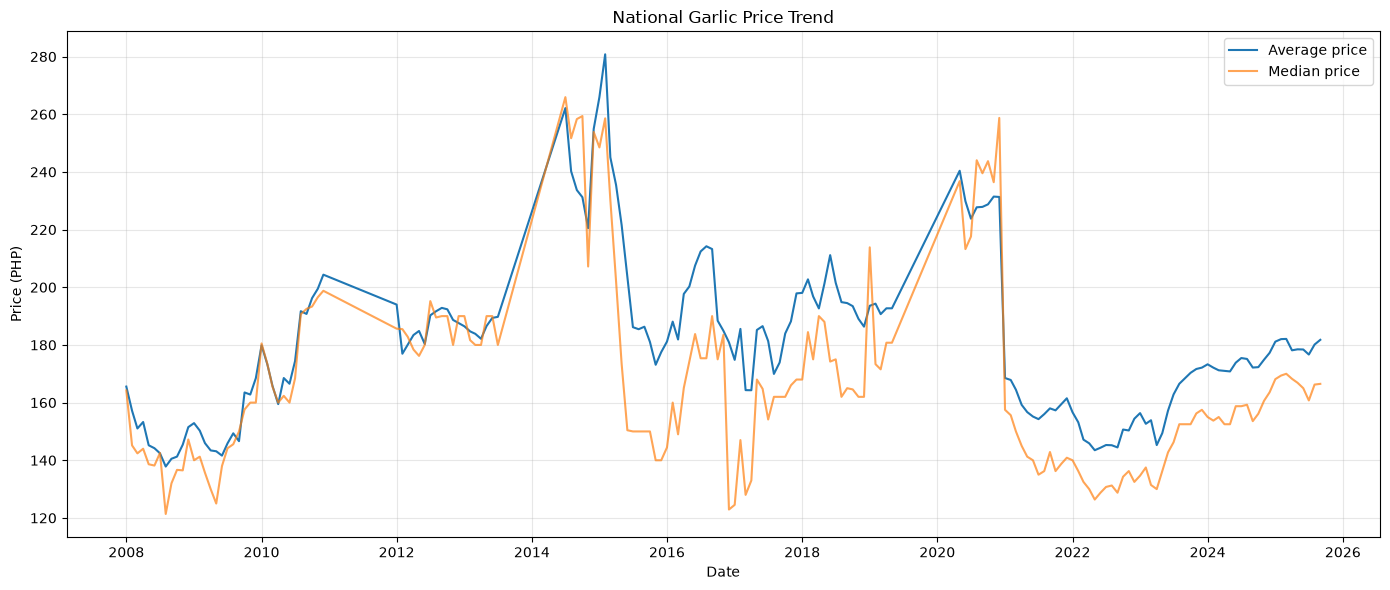

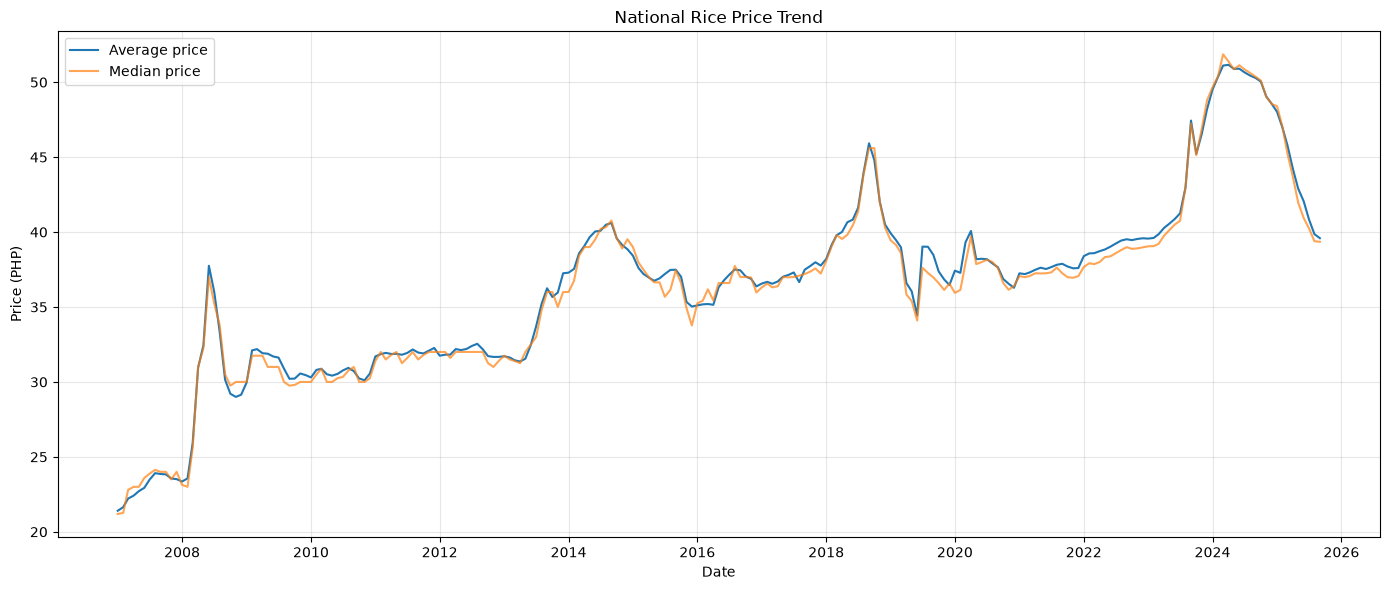

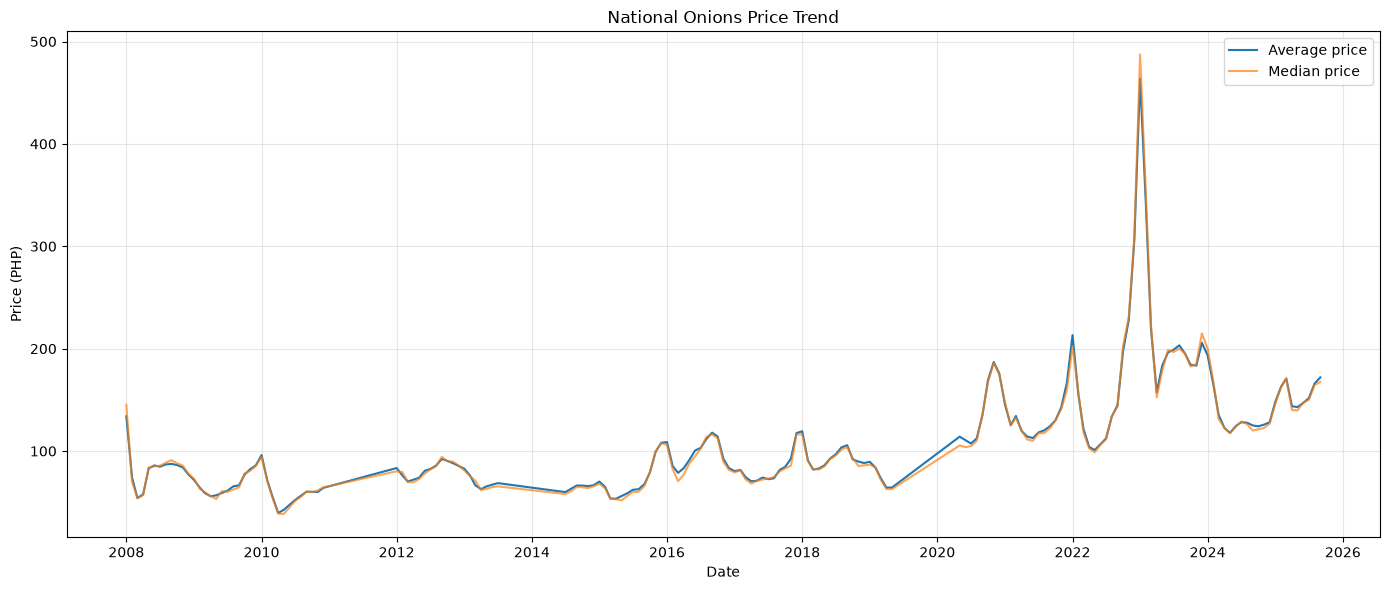

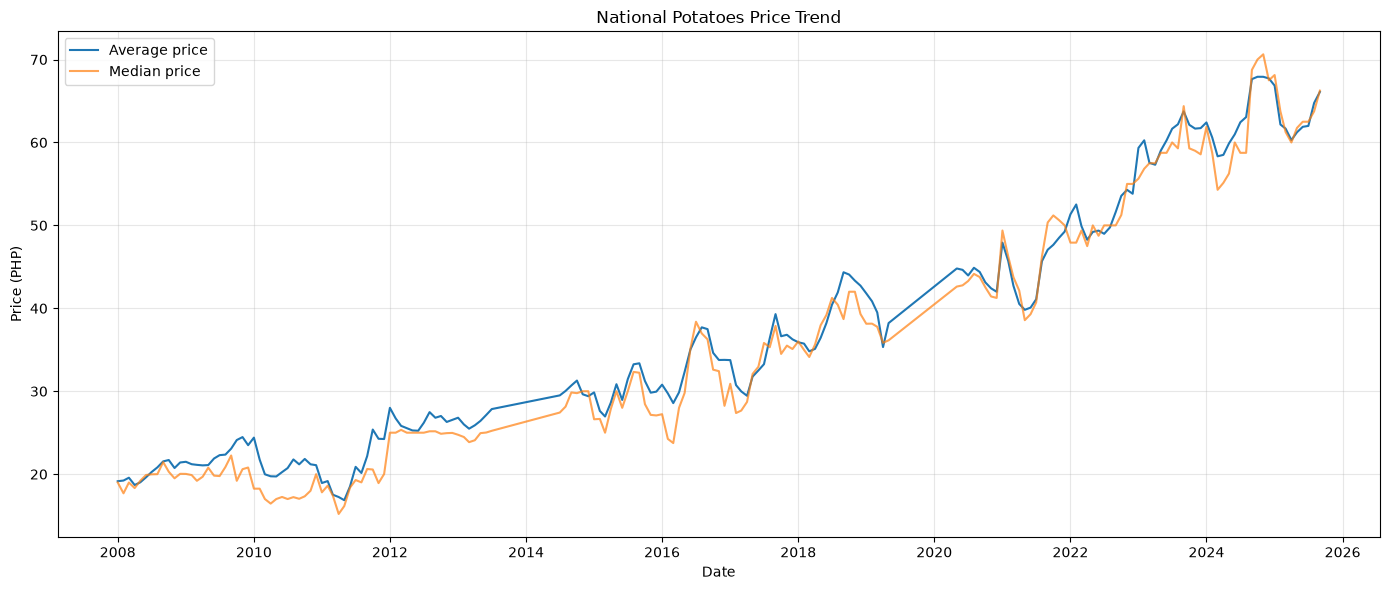

In [17]:
commodities = [
    row["commodity"]
    for row in national_df.select("commodity").distinct().collect()
]

for commodity in commodities:
    pdf = (
        national_df
        .filter(F.col("commodity") == commodity)
        .orderBy("price_date")
        .select("price_date", "avg_price", "median_price")
        .toPandas()
    )

    if pdf.empty:
        continue

    plt.figure(figsize=(14, 6))

    plt.plot(
        pdf["price_date"],
        pdf["avg_price"],
        label="Average price",
    )

    plt.plot(
        pdf["price_date"],
        pdf["median_price"],
        label="Median price",
        alpha=0.7,
    )

    plt.title(f"National {commodity.title()} Price Trend")
    plt.xlabel("Date")
    plt.ylabel("Price (PHP)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Results
- The prices for commodities have been steadily increasing.
- Some commodities experienced rapid price increases followed by sharp drops.
- Average and median prices generally follow similar trends across commodities, suggesting that price movements are relatively consistent across markets. However, eggs exhibit a notable divergence, where the average price experiences a sharp increase while the median continues to rise gradually. This may indicate unusually high prices in certain markets, pulling the average upward without substantially affecting the typical market price.

## Regional Price Distribution

In [20]:
latest_regional_dates = (
    regional_df
    .groupBy("commodity")
    .agg(F.max("price_date").alias("latest_date"))
)

latest_regional_prices = (
    regional_df.alias("r")
    .join(
        latest_regional_dates.alias("d"),
        (F.col("r.commodity") == F.col("d.commodity"))
        & (F.col("r.price_date") == F.col("d.latest_date")),
        "inner",
    )
    .select(
        F.col("r.adm1_name"),
        F.col("r.commodity"),
        F.col("r.price_date"),
        F.col("r.avg_price"),
        F.col("r.median_price"),
        F.col("r.markets_reporting"),
    )
)

commodities = [
    row["commodity"]
    for row in latest_regional_prices.select("commodity").distinct().collect()
]

for commodity in commodities:
    pdf = (
        latest_regional_prices
        .filter(F.col("commodity") == commodity)
        .orderBy(F.desc("avg_price"))
        .limit(5)
        .toPandas()
    )

    if pdf.empty:
        continue

    print(f"\n{commodity.title()} — Latest Regional Prices")
    display(pdf)


Cabbage — Latest Regional Prices


,adm1_name,commodity,price_date,avg_price,median_price,markets_reporting
0,Region V,cabbage,2025-09-01,154.190000,148.50,4
1,Region IV-B,cabbage,2025-09-01,151.666667,162.50,3
2,Region VI,cabbage,2025-09-01,126.670000,126.67,1
3,Region VIII,cabbage,2025-09-01,117.500000,117.50,1
4,Region III,cabbage,2025-09-01,114.753333,105.38,3



Tomatoes — Latest Regional Prices


,adm1_name,commodity,price_date,avg_price,median_price,markets_reporting
0,National Capital region,tomatoes,2025-09-01,132.870000,132.87,1
1,Region V,tomatoes,2025-09-01,128.605000,122.88,6
2,Region IV-A,tomatoes,2025-09-01,126.726000,127.25,5
3,Region IV-B,tomatoes,2025-09-01,119.583333,115.00,3
4,Region III,tomatoes,2025-09-01,113.805714,119.25,7



Beans — Latest Regional Prices


,adm1_name,commodity,price_date,avg_price,median_price,markets_reporting
0,Cordillera Administrative region,beans,2025-09-01,131.430000,131.43,1
1,National Capital region,beans,2025-09-01,130.300000,130.30,1
2,Region III,beans,2025-09-01,123.250000,117.50,4
3,Region XI,beans,2025-09-01,117.973333,113.25,3
4,Region V,beans,2025-09-01,116.500000,110.75,4


... (8 outputs left out)


Rice — Latest Regional Prices


,adm1_name,commodity,price_date,avg_price,median_price,markets_reporting
0,Region VI,rice,2025-09-01,41.751667,37.31,6
1,Region X,rice,2025-09-01,41.484000,40.50,5
2,Autonomous region in Muslim Mindanao,rice,2025-09-01,41.340000,39.08,4
3,Region VII,rice,2025-09-01,41.310000,40.83,4
4,Region IV-B,rice,2025-09-01,41.018000,40.09,5



Potatoes — Latest Regional Prices


,adm1_name,commodity,price_date,avg_price,median_price,markets_reporting
0,Region IV-A,potatoes,2025-09-01,90.00,90.00,1
1,National Capital region,potatoes,2025-09-01,87.42,87.42,1
2,Region V,potatoes,2025-09-01,67.88,67.88,1
3,Market Average,potatoes,2025-09-01,67.50,67.50,1
4,Cordillera Administrative region,potatoes,2025-09-01,64.30,66.25,5


### Results

- Cabbage: Region V recorded the highest average price at PHP 154.19/kg, closely followed by Region IV-B at PHP 151.67/kg. Region V also had the highest number of reporting markets (4). Region IV-B showed a notable difference between its average (PHP 151.67) and median (PHP 162.50), suggesting variation in market-level prices.

- Tomatoes: The National Capital Region recorded the highest average price at PHP 132.87/kg, followed by Region V at PHP 128.61/kg. Region III had the most reporting markets (7) but a lower average price of PHP 113.81/kg. Its median (PHP 119.25) was higher than its mean, suggesting some relatively low-priced markets pulled the average downward.

- Beans: The Cordillera Administrative Region recorded the highest average price at PHP 131.43/kg, followed closely by the National Capital Region at PHP 130.30/kg. Region III had the most reporting markets (4) among the listed regions. Its average (PHP 123.25) exceeded its median (PHP 117.50), indicating possible higher-priced markets influencing the regional average.

- Eggs: The Autonomous Region in Muslim Mindanao recorded the highest average price at PHP 12.09/kg, followed by Region VIII at PHP 10.20/kg. Region VIII had the highest number of reporting markets (6). Average and median prices were relatively close across all regions, suggesting less divergence in market-level prices.

- Carrots: Region IV-B recorded the highest average price at PHP 259.38/kg, followed by Region IV-A at PHP 256.75/kg. The National Capital Region had an average price of PHP 253.54/kg based on one reporting market. Region IV-B showed a substantial difference between its average (PHP 259.38) and median (PHP 218.75), suggesting considerable variation among reported market prices.

- Garlic: The National Capital Region recorded the highest average price at PHP 325.40/kg, considerably higher than the other listed regions. Region I followed at PHP 227.50/kg. Region IV-A showed a notable difference between its average (PHP 204.33) and median (PHP 160.00), potentially indicating unusually high prices in some reporting markets.

- Onions: Region VIII recorded the highest average price at PHP 192.47/kg, followed by Region X at PHP 180.83/kg. Region VI had the highest number of reporting markets (5). Average prices were generally higher than median prices, suggesting that some higher-priced markets may be pulling regional averages upward.

- Rice: Region VI recorded the highest average price at PHP 41.75/kg, closely followed by Region X at PHP 41.48/kg. Region VI also had the most reporting markets (6). Average prices were generally higher than median prices, suggesting some variation in market-level prices, although the differences were relatively modest.

- Potatoes: Region IV-A recorded the highest average price at PHP 90.00/kg, followed by the National Capital Region at PHP 87.42/kg. The Cordillera Administrative Region had the most reporting markets (5) and the lowest average price at PHP 64.30/kg. Its median (PHP 66.25) was slightly higher than its mean, indicating some relatively low-priced markets.

### Overall observations

- Regional price differences are evident across all commodities, suggesting that food prices are not uniform throughout the Philippines.
- Garlic and carrots exhibited particularly large differences between the highest and lower regional average prices.
- Some regions displayed substantial differences between average and median prices, potentially indicating market-level price variability or extreme observations.
- Rice exhibited comparatively small differences in average prices among the listed regions.
- The number of reporting markets varies considerably. Regional averages based on only one market should be interpreted cautiously because they may not adequately represent the entire region.

Note: All comparisons use the latest available regional observations for each commodity, dated September 1, 2025. Prices are assumed to be in PHP per kilogram, consistent with the dataset's price units.

In [23]:
commodities = [
    row["commodity"]
    for row in market_df.select("commodity").distinct().collect()
]

for commodity in commodities:

    latest_market_date = (
        market_df
        .filter(
            (F.col("commodity") == commodity)
            & F.col("price").isNotNull()
        )
        .agg(F.max("price_date").alias("latest_date"))
        .first()["latest_date"]
    )

    latest_market_prices = (
        market_df
        .filter(
            (F.col("commodity") == commodity)
            & (F.col("price_date") == latest_market_date)
            & F.col("price").isNotNull()
        )
    )

    print(f"\n{commodity.title()} — Latest Market Prices ({latest_market_date})")

    print("Highest prices:")
    display(
        latest_market_prices
        .orderBy(F.desc("price"))
        .select(
            "mkt_name",
            "adm1_name",
            F.round("price", 2).alias("price"),
        )
        .limit(5)
        .toPandas()
    )

    print("Lowest prices:")
    display(
        latest_market_prices
        .orderBy("price")
        .select(
            "mkt_name",
            "adm1_name",
            F.round("price", 2).alias("price"),
        )
        .limit(5)
        .toPandas()
    )


Cabbage — Latest Market Prices (2025-09-01)
Highest prices:


,mkt_name,adm1_name,price
0,Sorsogon,Region V,174.13
1,Oriental Mindoro,Region IV-B,168.75
2,Palawan,Region IV-B,162.50
3,Masbate,Region V,158.75
4,Basilan,Autonomous region in Muslim Mindanao,152.86


Lowest prices:


,mkt_name,adm1_name,price
0,Davao Oriental,Region XI,66.29
1,Ifugao,Cordillera Administrative region,72.14
2,Cagayan,Region II,72.50
3,Lanao del Sur,Autonomous region in Muslim Mindanao,73.25
4,Maguindanao,Autonomous region in Muslim Mindanao,75.63



Tomatoes — Latest Market Prices (2025-09-01)
Highest prices:


,mkt_name,adm1_name,price
0,Camarines Norte,Region V,147.00
1,Sorsogon,Region V,140.00
2,Camarines Sur,Region V,139.25
3,Cavite,Region IV-A,139.13
4,Metro Manila,National Capital region,132.87


... (26 outputs left out)


Potatoes — Latest Market Prices (2025-09-01)
Highest prices:


,mkt_name,adm1_name,price
0,Cavite,Region IV-A,90.00
1,Metro Manila,National Capital region,87.42
2,Benguet,Cordillera Administrative region,72.75
3,Albay,Region V,67.88
4,Abra,Cordillera Administrative region,67.50


Lowest prices:


,mkt_name,adm1_name,price
0,Davao de Oro,Region XI,47.50
1,Sulu,Autonomous region in Muslim Mindanao,50.63
2,Kalinga,Cordillera Administrative region,55.00
3,Ifugao,Cordillera Administrative region,60.00
4,Basilan,Autonomous region in Muslim Mindanao,60.71


### Results

- Cabbage: Sorsogon (Region V) recorded the highest market price at PHP 174.13/kg, followed by Oriental Mindoro at PHP 168.75/kg. Davao Oriental (Region XI) recorded the lowest at PHP 66.29/kg, followed by Ifugao at PHP 72.14/kg. The large difference between the highest and lowest prices suggests substantial geographic price variation.

- Tomatoes: Camarines Norte (Region V) recorded the highest price at PHP 147.00/kg, followed by Sorsogon at PHP 140.00/kg. South Cotabato (Region XII) recorded the lowest at PHP 52.50/kg, followed by Sultan Kudarat at PHP 53.75/kg. Region V appears repeatedly among the highest-priced markets, while Regions XI and XII appear among the lowest.

- Beans: Albay (Region V) recorded the highest price at PHP 137.50/kg, followed by Aurora at PHP 135.00/kg. Sarangani (Region XII) recorded the lowest at PHP 88.75/kg. The price differences are less pronounced than those observed in commodities such as cabbage, tomatoes, and carrots.

- Eggs: Tawi-Tawi (Autonomous Region in Muslim Mindanao) recorded the highest price at PHP 13.00/kg, followed by Lanao del Sur at PHP 12.38/kg. Quezon (Region IV-A) recorded the lowest at PHP 8.00/kg. The highest prices were concentrated in the Autonomous Region in Muslim Mindanao, while the lowest were observed in Regions III and IV-A.

- Carrots: Oriental Mindoro (Region IV-B) recorded the highest price at PHP 300.00/kg, followed by Quezon at PHP 287.50/kg. Bukidnon (Region X) recorded the lowest at PHP 68.75/kg. Carrots exhibited one of the largest geographic price differences among the commodities, with the highest price more than four times the lowest.

- Garlic: Metro Manila (National Capital Region) recorded the highest price at PHP 325.40/kg, followed by Rizal at PHP 305.00/kg. Bulacan (Region III) recorded the lowest at PHP 129.67/kg, followed by South Cotabato at PHP 130.00/kg. The substantial price differences suggest considerable geographic variation, particularly between Metro Manila and some provincial markets.

- Onions: Camiguin (Region X) recorded the highest price at PHP 212.50/kg, followed by Eastern Samar at PHP 208.00/kg. Batangas (Region IV-A) recorded the lowest at PHP 137.50/kg. Higher-priced markets were concentrated in Regions VIII, X, and V, while relatively lower prices appeared in Regions IV-A, III, and XI.

- Rice: Negros Occidental (Region VI) recorded the highest price at PHP 48.41/kg, followed by Davao City at PHP 47.87/kg. Quirino (Region II) recorded the lowest at PHP 30.57/kg, followed by Apayao at PHP 31.00/kg. Regions VI, XI, and X appeared among the highest-priced markets, while Region II accounted for three of the five lowest-priced markets.

- Potatoes: Cavite (Region IV-A) recorded the highest price at PHP 90.00/kg, followed by Metro Manila at PHP 87.42/kg. Davao de Oro (Region XI) recorded the lowest at PHP 47.50/kg. The highest prices were observed in Regions IV-A and NCR, while some of the lowest were found in Regions XI and the Autonomous Region in Muslim Mindanao.

### Overall observations

- Geographic price variation: All commodities exhibit differences between their highest- and lowest-priced markets, although the magnitude varies considerably.
- Carrots and garlic: These commodities show particularly large price gaps, suggesting substantial differences in local market pricing.
- Regional patterns: Region V repeatedly appears among the highest-priced markets for cabbage, tomatoes, and beans. Meanwhile, Regions XI and XII frequently appear among the lower-priced markets.
- Rice: Region II accounts for three of the five lowest-priced rice markets, suggesting a possible geographic concentration of relatively inexpensive rice.
- Market accessibility and distribution: Geographic differences may reflect transportation costs, supply availability, production locations, and distribution networks.
- Further investigation: Markets with unusually high or low prices could be examined alongside historical price trends to determine whether these differences are persistent or temporary.

Important considerations:
- Price differences indicate geographic variation but do not independently establish its causes.

## Commodity Price Growth and Volatility

In [27]:
window = (
    Window
    .partitionBy("commodity")
    .orderBy("price_date")
)

monthly_changes = (
    national_df
    .withColumn(
        "previous_month_price",
        F.lag("avg_price").over(window),
    )
    .withColumn(
        "previous_month_date",
        F.lag("price_date").over(window),
    )
    .withColumn(
        "months_between",
        F.months_between(
            F.col("price_date"),
            F.col("previous_month_date"),
        ),
    )
    .withColumn(
        "price_change_pct",
        F.when(
            (F.col("previous_month_price") > 0)
            & (F.col("months_between") == 1),
            F.round(
                (
                    (F.col("avg_price") - F.col("previous_month_price"))
                    / F.col("previous_month_price")
                ) * 100,
                2,
            ),
        ),
    )
)

commodities = [
    row["commodity"]
    for row in monthly_changes.select("commodity").distinct().collect()
]

for commodity in commodities:
    pdf = (
        monthly_changes
        .filter(
            (F.col("commodity") == commodity)
            & F.col("price_change_pct").isNotNull()
        )
        .orderBy(F.desc("price_change_pct"))
        .select(
            "price_date",
            "avg_price",
            "previous_month_price",
            "price_change_pct",
        )
        .toPandas()
    )

    if pdf.empty:
        continue

    print(f"\n{commodity.title()} — Largest Monthly Increase")
    display(pdf.head(5))

    print(f"{commodity.title()} — Largest Monthly Decrease")
    display(pdf.tail(5).sort_values("price_change_pct"))


Cabbage — Largest Monthly Increase


,price_date,avg_price,previous_month_price,price_change_pct
0,2019-05-01,64.927000,48.293590,34.44
1,2020-11-01,78.503268,61.715579,27.20
2,2018-09-01,96.781204,77.143887,25.46
3,2020-12-01,97.636924,78.503268,24.37
4,2015-05-01,44.685104,36.591042,22.12


Cabbage — Largest Monthly Decrease


,price_date,avg_price,previous_month_price,price_change_pct
186,2010-01-01,29.966000,49.855333,-39.89
185,2013-08-01,27.930000,41.160612,-32.14
184,2017-02-01,43.809733,53.088867,-17.48
183,2019-01-01,51.815182,62.294139,-16.82
182,2018-10-01,80.747542,96.781204,-16.57



Tomatoes — Largest Monthly Increase


,price_date,avg_price,previous_month_price,price_change_pct
0,2024-07-01,117.001200,68.547600,70.69
1,2019-05-01,47.978235,30.017059,59.84
2,2024-11-01,121.548800,77.996267,55.84
3,2012-04-01,42.966250,30.176250,42.38
4,2021-07-01,62.923421,44.629605,40.99


... (26 outputs left out)


Potatoes — Largest Monthly Increase


,price_date,avg_price,previous_month_price,price_change_pct
0,2012-01-01,27.998824,24.237500,15.52
1,2011-10-01,25.380000,22.177500,14.44
2,2021-01-01,47.920833,41.992987,14.12
3,2011-07-01,20.882500,18.527500,12.71
4,2021-08-01,45.677500,41.090833,11.16


Potatoes — Largest Monthly Decrease


,price_date,avg_price,previous_month_price,price_change_pct
187,2010-02-01,21.750000,24.407500,-10.89
186,2019-04-01,35.325294,39.498235,-10.56
185,2011-01-01,18.930000,21.082500,-10.21
184,2017-02-01,30.740625,33.754375,-8.93
183,2011-03-01,17.520000,19.167500,-8.60


In [26]:
monthly_changes.filter(
    F.col("price_change_pct").isNotNull()
).orderBy(
    F.desc("price_change_pct")
).select(
    "commodity",
    "price_date",
    "previous_month_price",
    "avg_price",
    "price_change_pct",
).limit(20).toPandas()

,commodity,price_date,previous_month_price,avg_price,price_change_pct
0,tomatoes,2024-07-01,68.547600,117.001200,70.69
1,tomatoes,2019-05-01,30.017059,47.978235,59.84
2,tomatoes,2024-11-01,77.996267,121.548800,55.84
3,onions,2023-01-01,306.330000,463.717581,51.38
4,onions,2008-05-01,57.678750,83.092353,44.06
5,tomatoes,2012-04-01,30.176250,42.966250,42.38
6,tomatoes,2021-07-01,44.629605,62.923421,40.99
7,tomatoes,2020-11-01,73.095625,102.242158,39.87
8,tomatoes,2013-05-01,28.835882,40.207917,39.44
9,tomatoes,2010-04-01,20.740000,28.700000,38.38


### Results

- Tomatoes experienced the most significant monthly price increases, accounting for the majority of the 20 largest increases. The largest occurred in July 2024, when the national average price increased from PHP 68.55 to PHP 117.00, representing a 70.69% increase in one month.
- Onions also experienced substantial price increases, with the largest occurring in January 2023 at 51.38%, increasing from PHP 306.33 to PHP 463.72. Another significant increase occurred in May 2008, reaching 44.06%.
- Eggs recorded a notable monthly increase in August 2015, with prices rising by 36.77%, from PHP 6.58 to PHP 9.00.
- Cabbage experienced a significant increase in May 2019, rising by 34.44% from PHP 48.29 to PHP 64.93.
- Carrots recorded a substantial increase in September 2017, with prices rising by 29.35%, from PHP 70.08 to PHP 90.65.
- Tomato prices appear particularly volatile, with several large monthly increases occurring across different years, including 2009, 2010, 2012, 2013, 2019, 2020, 2021, 2023, and 2024.
- Recent price increases are particularly noticeable for tomatoes and onions, with several of their largest recorded increases occurring between 2022 and 2024.

### Overall observations

- Tomatoes dominate the largest monthly price increases, suggesting that they exhibit considerable short-term price volatility compared with other commodities.
- Onions also demonstrate substantial price fluctuations, particularly during 2022–2023.
- Price increases are not limited to recent years, as significant monthly changes also occurred between 2008 and 2019.
- The magnitude of some monthly increases suggests that certain commodities may be more susceptible to seasonal supply changes or temporary market disruptions.

In [28]:
commodity_volatility = (
    monthly_changes
    .filter(F.col("price_change_pct").isNotNull())
    .groupBy("commodity")
    .agg(
        F.avg("price_change_pct").alias("avg_monthly_change_pct"),
        F.stddev("price_change_pct").alias("monthly_volatility_pct"),
        F.max("price_change_pct").alias("largest_increase_pct"),
        F.min("price_change_pct").alias("largest_decrease_pct"),
    )
    .orderBy(F.desc("monthly_volatility_pct"))
)

commodity_volatility.toPandas()

,commodity,avg_monthly_change_pct,monthly_volatility_pct,largest_increase_pct,largest_decrease_pct
0,tomatoes,2.559829,18.550771,70.69,-44.17
1,onions,0.600000,12.955631,51.38,-44.78
2,cabbage,0.511872,10.269251,34.44,-39.89
3,carrots,0.542179,9.708598,29.35,-24.20
4,potatoes,0.644628,4.502972,15.52,-10.89
5,garlic,-0.128686,4.352689,15.59,-27.15
6,eggs,0.190106,3.971984,36.77,-25.26
7,rice,0.315714,2.929904,19.47,-9.65
8,beans,0.063131,0.856099,2.72,-2.63


### Results

- Tomatoes exhibited the highest price volatility, with an average monthly price change of 2.56% and volatility of 18.55%. Its largest monthly increase reached 70.69%, while its largest decrease was -44.17%, indicating substantial short-term price fluctuations.

- Onions were the second most volatile commodity, with 12.96% monthly volatility. They recorded the largest single-month increase after tomatoes (+51.38%) and the largest decrease among all commodities (-44.78%).

- Cabbage and carrots also showed considerable price fluctuations, with monthly volatility of 10.27% and 9.71%, respectively. Both experienced monthly increases exceeding 29% and decreases exceeding 24%.

- Potatoes, garlic, and eggs had moderate volatility, ranging from approximately 4% to 4.5%. Garlic was the only commodity with a negative average monthly change (-0.13%), suggesting a slight downward tendency over the observation period.

- Rice showed relatively stable prices, with 2.93% monthly volatility and an average monthly increase of 0.32%. Its largest increase was 19.47%, compared with a largest decrease of -9.65%.

- Beans were the most stable commodity, recording only 0.86% monthly volatility. Its largest increase (+2.72%) and decrease (-2.63%) were also considerably smaller than those of the other commodities.

### Key observations

1. Vegetables generally experienced greater price instability. Tomatoes, onions, cabbage, and carrots occupied the top four positions in monthly volatility.
2. Beans and rice were comparatively stable. Their monthly price movements were substantially smaller than those of the more volatile commodities.
3. Average monthly change and volatility measure different things. Tomatoes had the highest average increase and volatility, while onions had a relatively small average increase despite substantial fluctuations.
4. Extreme price movements are not necessarily representative of typical behavior. The largest increases and decreases capture individual monthly events, whereas volatility summarizes the variation across all observed monthly changes.

Overall: Tomato, onion, cabbage, and carrot prices were considerably more volatile than the other commodities. This suggests that price stability differs substantially by commodity, making volatility a useful metric for identifying which food products may require closer monitoring.

## Seasonal Patterns

In [32]:
annual_commodity_average = (
    national_df
    .withColumn("year", F.year("price_date"))
    .groupBy("commodity", "year")
    .agg(
        F.avg("avg_price").alias("annual_avg_price")
    )
)

seasonal_prices = (
    national_df
    .withColumn("year", F.year("price_date"))
    .withColumn("month", F.month("price_date"))
    .join(
        annual_commodity_average,
        ["commodity", "year"],
        "inner",
    )
    .withColumn(
        "price_index",
        F.col("avg_price") / F.col("annual_avg_price") * 100,
    )
    .groupBy("commodity", "month")
    .agg(
        F.avg("price_index").alias("avg_seasonal_index")
    )
    .orderBy("commodity", "month")
)

seasonal_extremes = (
    seasonal_prices
    .groupBy("commodity")
    .agg(
        F.min_by("month", "avg_seasonal_index").alias("lowest_month"),
        F.min("avg_seasonal_index").alias("min_seasonal_index"),
        F.max_by("month", "avg_seasonal_index").alias("highest_month"),
        F.max("avg_seasonal_index").alias("max_seasonal_index"),
    )
    .orderBy("commodity")
)

seasonal_extremes.toPandas()

,commodity,lowest_month,min_seasonal_index,highest_month,max_seasonal_index
0,beans,6,99.519632,12,100.837454
1,cabbage,3,87.312319,11,109.998625
2,carrots,4,88.804285,9,109.955829
3,eggs,6,97.903588,8,101.855182
4,garlic,4,98.001856,1,102.791251
5,onions,4,81.961029,1,126.444892
6,potatoes,4,92.392903,10,106.471555
7,rice,1,97.326158,9,101.872384
8,tomatoes,3,77.996804,12,118.010292


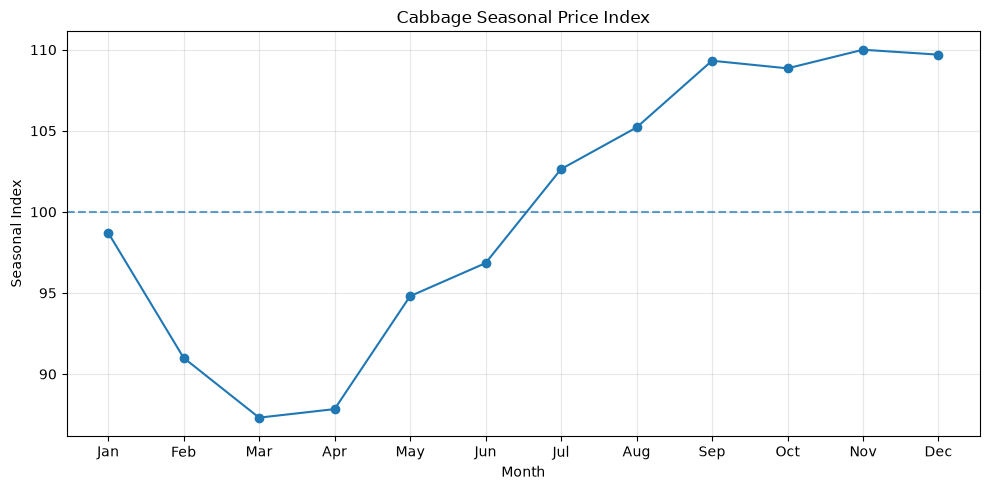

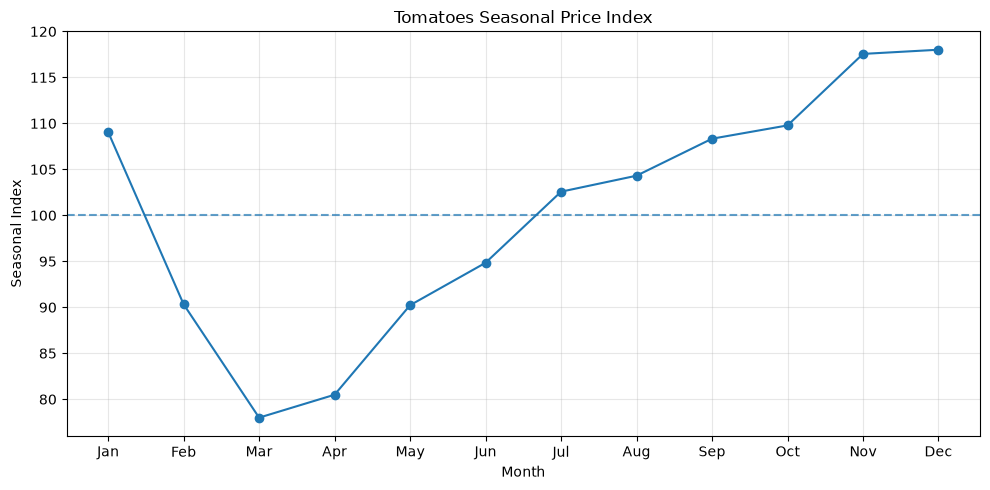

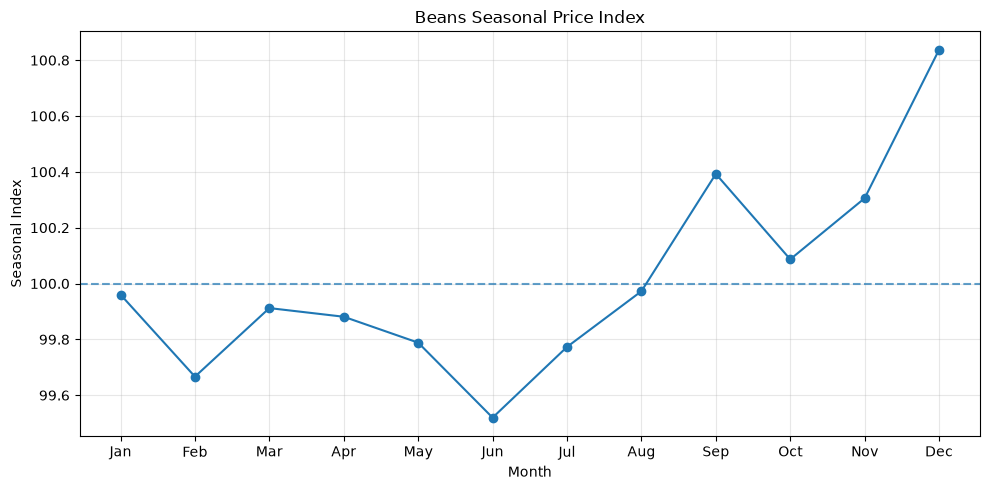

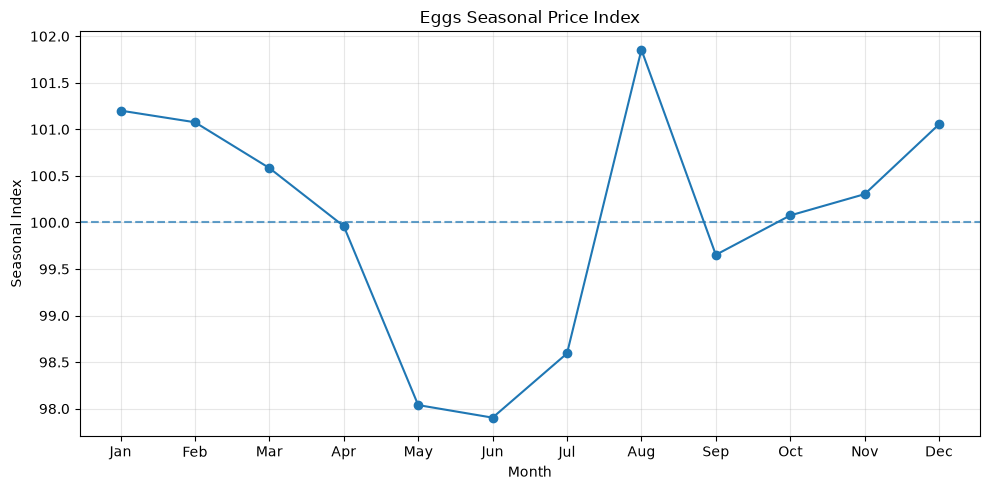

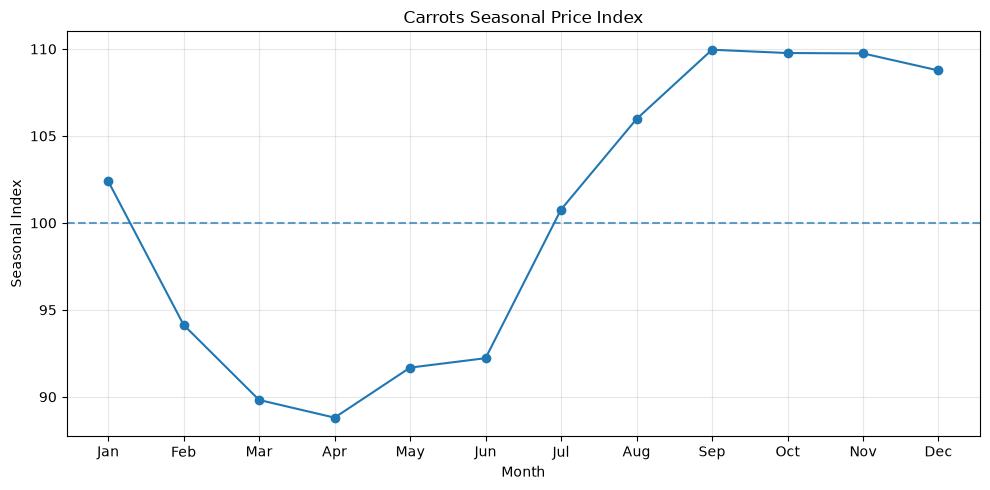

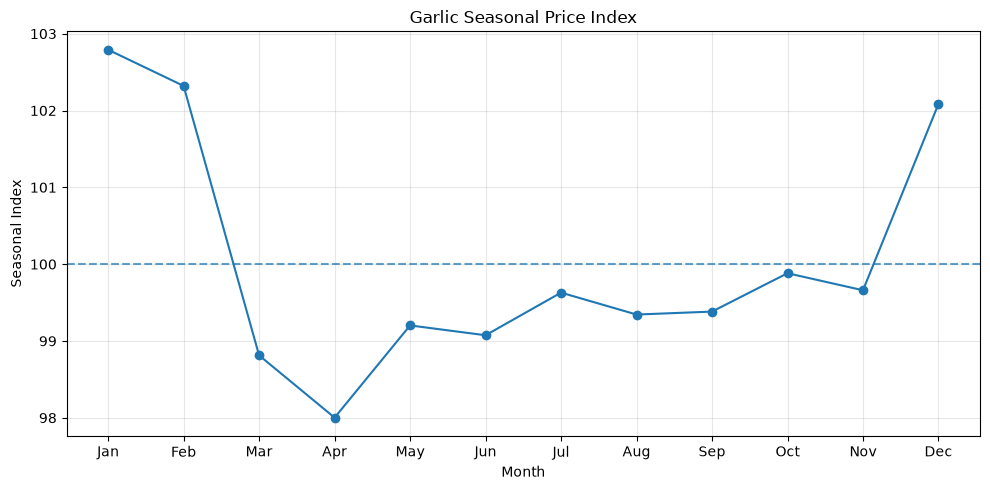

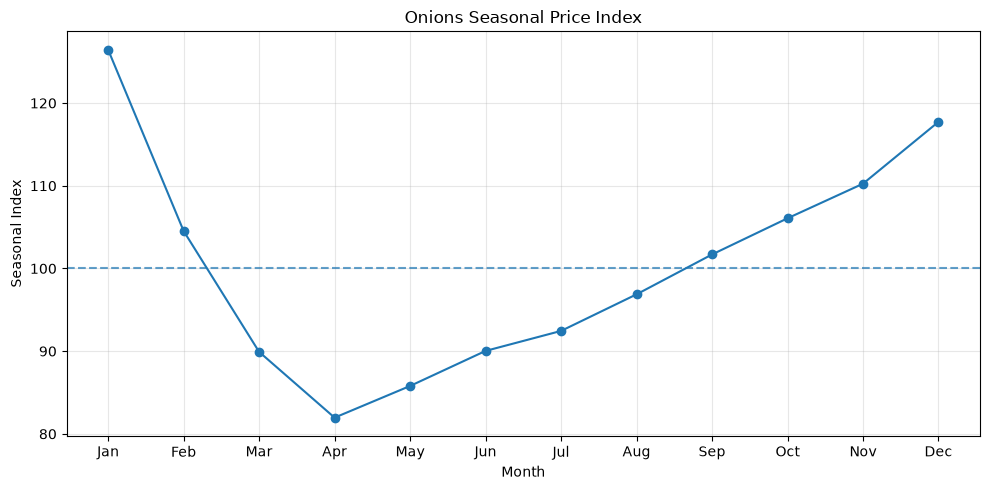

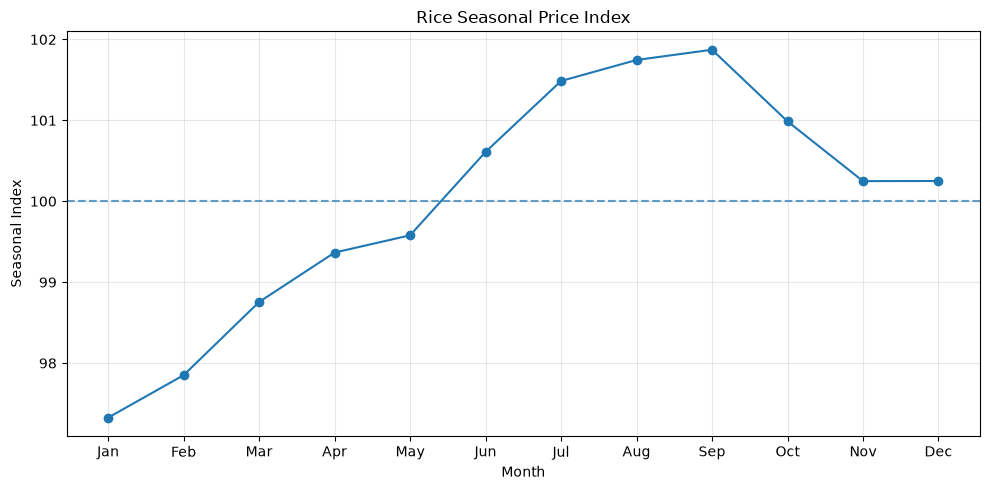

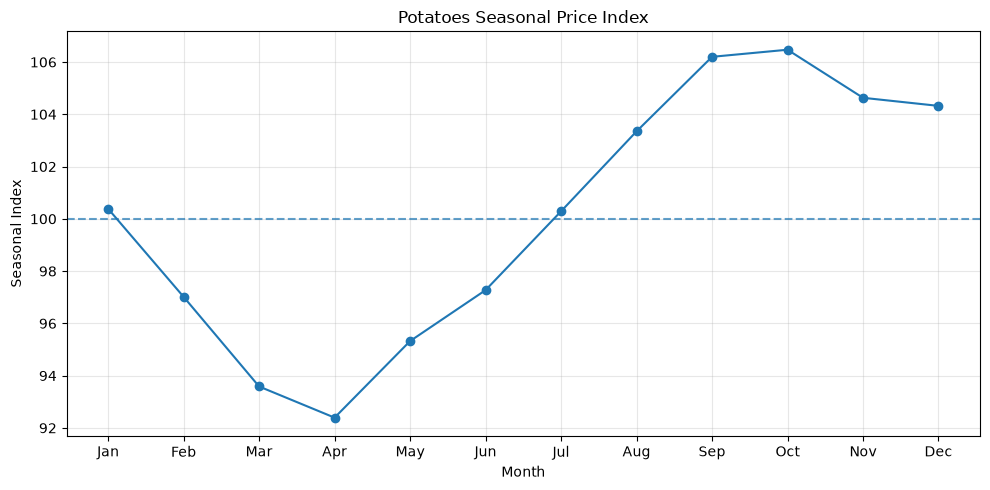

In [33]:
commodities = [
    row["commodity"]
    for row in seasonal_prices.select("commodity").distinct().collect()
]

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

for commodity in commodities:
    pdf = (
        seasonal_prices
        .filter(F.col("commodity") == commodity)
        .orderBy("month")
        .toPandas()
    )

    plt.figure(figsize=(10, 5))

    plt.plot(
        pdf["month"],
        pdf["avg_seasonal_index"],
        marker="o",
    )

    plt.axhline(100, linestyle="--", alpha=0.7)

    plt.xticks(range(1, 13), month_labels)

    plt.title(f"{commodity.title()} Seasonal Price Index")
    plt.xlabel("Month")
    plt.ylabel("Seasonal Index")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Metrics
- The index scores measure how close a certain commodity's price is to that year's average price (with index score of 100).
- A score below 100 (<100) indicates that the commodity was cheaper than its average price.
- A score above 100 (>100) indicates that the commodity was more expensive than its average price.

### Results
- Beans: Lowest in June (99.52); highest in December (100.84).
 
- Cabbage: Lowest in March (87.31); highest in November (110.00).
 
- Carrots: Lowest in April (88.80); highest in September (109.96).

- Eggs: Lowest in June (97.90); highest in August (101.86).

- Garlic: Lowest in April (98.00); highest in January (102.79).

- Onions: Lowest in April (81.96); highest in January (126.44).

- Potatoes: Lowest in April (92.39); highest in October (106.47).

- Rice: Lowest in January (97.33); highest in September (101.87).

- Tomatoes: Lowest in March (78.00); highest in December (118.01).

### Key observations

- Onions exhibit the strongest seasonal variation, ranging from 81.96 to 126.44.

- Tomatoes also show substantial seasonality, with prices peaking in December.

- Rice and eggs have relatively stable seasonal price indices throughout the year.

- Beans are the most stable commodity, with only a slight variation between the highest and lowest index.

## Cumulative Price Increase

In [34]:
growth_df.orderBy(
    F.desc("price_increase_pct")
).toPandas()

,commodity,currency,start_date,end_date,start_price,end_price,price_increase,price_increase_pct
0,potatoes,PHP,2008-01-01,2025-09-01,19.150588,66.095000,46.944412,245.13
1,carrots,PHP,2008-01-01,2025-09-01,59.358750,178.184889,118.826139,200.18
2,cabbage,PHP,2008-01-01,2025-09-01,36.604000,108.897568,72.293568,197.50
3,tomatoes,PHP,2008-01-01,2025-09-01,39.464706,93.614416,54.149710,137.21
4,eggs,PHP,2008-01-01,2025-09-01,4.280000,9.334583,5.054583,118.10
5,rice,PHP,2007-01-01,2025-09-01,21.402857,39.591325,18.188468,84.98
6,beans,PHP,2012-05-01,2025-09-01,79.230000,111.924375,32.694375,41.27
7,onions,PHP,2008-01-01,2025-09-01,134.022000,171.960441,37.938441,28.31
8,garlic,PHP,2008-01-01,2025-09-01,165.556667,181.770976,16.214309,9.79


### Results

- Potatoes: Increased from PHP 19.15 to PHP 66.10 (+245.13%), the largest cumulative price increase.
- Carrots: Increased from PHP 59.36 to PHP 178.18 (+200.18%).
- Cabbage: Increased from PHP 36.60 to PHP 108.90 (+197.50%).
- Tomatoes: Increased from PHP 39.46 to PHP 93.61 (+137.21%).
- Eggs: Increased from PHP 4.28 to PHP 9.33 (+118.10%).
- Rice: Increased from PHP 21.40 to PHP 39.59 (+84.98%).
- Beans: Increased from PHP 79.23 to PHP 111.92 (+41.27%).
- Onions: Increased from PHP 134.02 to PHP 171.96 (+28.31%).
- Garlic: Increased from PHP 165.56 to PHP 181.77 (+9.79%), the smallest cumulative price increase.

### 1. Which commodities had the largest cumulative price increases?

Potatoes experienced the largest cumulative price increase at 245.13%, followed by carrots (200.18%) and cabbage (197.50%).

These results suggest that root vegetables and certain leafy vegetables experienced substantial long-term price increases over the observation period.

### 2. Which commodities experienced the smallest increases?

Garlic had the smallest cumulative price increase at 9.79%, followed by onions (28.31%) and beans (41.27%).

Despite having relatively high starting prices, garlic and onions experienced comparatively smaller percentage increases than the other commodities.

### 3. Do the results correspond to the trends observed earlier?

- Potatoes, carrots, and cabbage experienced substantial long-term price increases. Their seasonal indices also show noticeable fluctuations, particularly cabbage and carrots.
- Tomatoes experienced a considerable cumulative increase (137.21%) and strong seasonal variation, with prices peaking in December (118.01) and reaching their lowest in March (78.00).
- Onions had a relatively small cumulative increase (28.31%) despite exhibiting the strongest seasonal variation, with its seasonal index ranging from 81.96 to 126.44.
- Rice and eggs had moderate cumulative increases and relatively stable seasonal indices, suggesting less pronounced seasonal price fluctuations.
- Garlic had the smallest cumulative increase (9.79%) and relatively limited seasonal variation.

Overall, the results suggest that long-term price increases and seasonal price fluctuations are not necessarily correlated. A commodity can experience substantial long-term inflation without having equally pronounced seasonal fluctuations, and vice versa.